# Business and Analytical Context

## Data Understanding

### 1. Project: Mental Health in Technology-related Jobs

#### 1.1 Purpose

This notebook investigates the OSMI 2016 Mental Health in Tech survey dataset to establish whether it is suitable for unsupervised clustering.

The analysis examines the dataset's structure, data types, distributions, missingness, response quality, inconsistencies, conditional survey logic, and relationships between related variables.

The objective is not to prepare the final clustering matrix in this notebook. Instead, it is to establish a defensible understanding of the data and document the exact transformations, exclusions, and feature-engineering decisions required during **data preparation**.

#### 1.2 Analytical Objectives

The investigation addresses the following questions:
1. What does the dataset contain, and what is its structure?
2. Which variables describe respondents, their employment circumstances, workplace mental-health environments, and personal mental-health experiences?
3. How much missingness exists, and which missing values are explained by survey routing?
4. Which variables contain inconsistent, malformed, ambiguous, or non-standardised responses?
5. Which columns contain multiple selections in a single response?
6. Which variables are redundant, excessively sparse, high-cardinality, or unsuitable for clustering?
7. Which variables should be retained, transformed, excluded from clustering, or removed?
8. What decisions must be implemented during data prepartion?

#### 1.3 Clustering Considerations

Four clustering approaches will be investigated, each using a data representation and validation strategy appropriate to its underlying assumptions.

The dataset is predominantly categorical. However, different clustering algorithms interpret categorical information differently. Consequently, the project will investigate both directional clustering and methods that transform categorical observations into alternative representations.

The selected approaches are:

##### 1.3.1 K-Modes - Raw Categorical Data

K- Modes is a centroid-based clustering algorithm designed specifically for categorical data. It uses matching dissimilarity rather than Euclidean distance and represents cluster centres using categorical modes.

Its performance will be evaluated using:
- **Cost/Inertial (Dissimilarity Sum):** The total number of categorical mismatches between observations and their assigned cluster modes. Lower values indicate lower within-cluster dissimilarity. This will be used as the primary elbow-method criterion for selecting the number of clusters.
- **Normalized Mutual Information (NMI) - Stability:** K-Modes will be fitted repeatedly using different random seeds. NMI will compare the resulting cluster assignments. Higher values indicate greater agreement between runs and therefore more stable clustering.
- **Cluster Purity (Feature Dominance):** The distribution of categorical responses within each cluster will be examined to determine whether particular features are disproportionately dominant. This will help establish whether the resulting clusters represent distinct and interpretable respondent profile.

Traditional geometric validation metrics will not be applied directly to the new categorical representation.

##### 1.3.2 K-Means - MCA Components

Multiple Correspondence Analysis (MCA) will transform the categorical variables into continuous numerical coordinates. K-Means will then be applied to the resulting MCA component space.

Its performance will be evaluated using:
- **Silhouette Coefficient:** Measures how well observations fit within their assigned clusters relative to other clusters. Values range from -1 to 1, with higher values generally better separation.
- **Davies-Bouldin Index:** Evaluates the relationship between within-cluster dispersion and separation between clusters. Lower values indicate more distnct clusters.
- **Calinski-Harabasz Index (Variance Ratio Criterion):** Compares between-cluster dispersion with within-cluster dispersion. Higher values generally indicate better-defined clusters.

These geometric metrics are appropriate for the continuous MCA representation, rather than the original categorical observations.

##### 1.3.3 Agglomerative Hierarchical Clustering - Gower Distance

Gower distance will be used to calculate pairwise dissmilarities between observations. It accomodates mixed data types and provides a distance representation suitable for hierarchical clustering.

Its performance will be evaluated using:
- **Cophenetic Correlation Coefficient (CPCC):** Measures the correlation between the original Gower dissimilarities and the cophenetic distances represented by the hierarchical dendrogram. Higher values indicate that the tree better preserves the original pairwise dissimilarities.
- **Silhouette Coefficient (Gower Distance):** The precomputed Gower distance matrix will be supplied directly to the silhouette calculation. Higher values generally indicate better-defined clusters.
- **Hubert's Γ (Gamma) Statistic:*** Evaluates the association between the original pairwise dissimilarities and a model derived from the cluster structure. Higher values indicate stronger agreement between the distance structure and the clustering.

The hierarchical linkage method and its compatibility with the Gower distance representation will be considered when fitting the model.

##### 1.3.4 HDBSCAN - UMAP Embeddings

Uniform Manifold Approximation and Projection (UMAP) will be used to construct a lower-dimensional embedding of the prepared data. HDBSCAN will then identify dense regions in the embedding space without requiring a predefined number of clusters.

HDBSCAN can identify clusters with non-spherical shapes and assign observations that do not belong to sufficiently dense regions to a noise label (-1).

Its perfomance will be evaluated using:
- **Density-Based Clustering Validation (DBCV):** Evaluates cluster density and separation without assuming spherical cluster shapes. Values range from -1 to 1, with higher values generally indicating better density-based cluster validity.
- **Noise Percentage/Coverage:** The proportion if observations assigned the noise label (-1) will be monitored. This indicates how much of the dataset HDBSCAN can assign to clusters. A noise proportion around or below 20-30% will be used as an initial diagnostic target, not as a universal requirement.
- **Cluster Validity and Density Structure:** Cluster persistence, density separation, and the validity of individual clusters will be examined to determine whether the embedding and density parameters produce meaningful groups rather than artificial subdivisions.

The UMAP representation and HDBSCAN parameters will be assessed together because the embedding influences the density structure on which HDBSCAN operates.

#### 1.4 Comparative Evaluation

The four approaches will not be compared using a single metric because they operate on different representations and rely on different clustering assumptions.

Each method will first be evaluated using its appropriate internal validation measures. The final comparison will consider:
- Cluster separation and cohesion.
- Stability and reproducibility.
- Cluster size and distribution.
- Noise or unassigned observations, where applicable.
- Feature dominance and interpretability.
- Whether the resulting clusters represent meaningful respondent profiles.
- Sensitivity to model and representation parameters.

The objective is to select a clustering solution that is statistically defensible, stable, interpretable, and appropriate for the structure of the survey data.

#### 1.5 Scope and Ethical Considerations

The survey includes sensitive mental-health information. The analysis will not interpret survey responses as clinical diagnoses, infer medical conditions, or treat demographic characteristics as indicators of mental-health status.

The clustering objective is to identify patterns in survey responses and workplace experiences, not to diagnose individuals or make decisions about their employment.

### 2. Import Libraries and Load the Dataset



In [ ]:
from pathlib import Path

import math
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")

data_path = "../data/raw/mental-heath-in-tech-2016_20161114.csv"
FIGURES_PATH = "../reports/figures/data_understanding"

df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
df.head(20)

Dataset shape: 1,433 rows x 63 columns


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",Do you think that discussing a mental health disorder with your employer would have negative consequences?,Do you think that discussing a physical health issue with your employer would have negative consequences?,Would you feel comfortable discussing a mental health disorder with your coworkers?,Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?,Do you feel that your employer takes mental health as seriously as physical health?,Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?,Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,Do you know local or online resources to seek help for a mental health disorder?,"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?","If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?","If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?","If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",Do you believe your productivity is ever affected by a mental health issue?,"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",Do you have previous employers?,Have your previous employers provided mental health benefits?,Were you aware of the options for mental health care provided by your previous employers?,Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?,Did your previous employers provide resources to learn more about mental health issues and how to seek help?,Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?,Do you think that discussing a mental health disorder with previous employers would have negative consequences?,Do you think that discussing a physical health issue with previous employers would have negative consequences?,Would you have been willing to discuss a mental health issue with your previous co-workers?,Would you have been willing to discuss a mental health issue with your direct supervisor(s)?,Did you feel that your previous employers took mental health as seriously as physical health?,Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?,Would you be willing to bring up a physical health issue with a potential employer in an interview?,Why or why not?,Would you bring up a mental health issue with a potential employer in an interview?,Why or why not?.1,Do you feel that being identified as a person with a mental health issue would hurt your career?,Do you think that team members/co-workers would view you more negatively if they knew you suffered from a menta

In [2]:
df.columns.tolist()

['Are you self-employed?',
 'How many employees does your company or organization have?',
 'Is your employer primarily a tech company/organization?',
 'Is your primary role within your company related to tech/IT?',
 'Does your employer provide mental health benefits as part of healthcare coverage?',
 'Do you know the options for mental health care available under your employer-provided coverage?',
 'Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?',
 'Does your employer offer resources to learn more about mental health concerns and options for seeking help?',
 'Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?',
 'If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:',
 'Do you think that discussing a mental health disorder with your employer would have neg

In [5]:
column_name_mapping = {
    'Are you self-employed?': 'self_employed',
    'How many employees does your company or organization have?': 'company_size',
    'Is your employer primarily a tech company/organization?': 'tech_company',
    'Is your primary role within your company related to tech/IT?': 'tech_role',
    'Does your employer provide mental health benefits as part of healthcare coverage?': 'mh_benefits',
    'Do you know the options for mental health care available under your employer-provided coverage?': 'mh_options_awareness',
    'Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?': 'mh_formal_discussion',
    'Does your employer offer resources to learn more about mental health concerns and options for seeking help?': 'mh_resources_offered',
    'Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?': 'mh_anonymity_protected',
    'If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:': 'mh_medical_leave_ease',
    'Do you think that discussing a mental health disorder with your employer would have negative consequences?': 'mh_discussion_consequences',
    'Do you think that discussing a physical health issue with your employer would have negative consequences?': 'ph_discussion_consequences',
    'Would you feel comfortable discussing a mental health disorder with your coworkers?': 'mh_comfort_coworkers',
    'Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?': 'mh_comfort_supervisor',
    'Do you feel that your employer takes mental health as seriously as physical health?': 'mh_vs_ph_seriousness',
    'Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?': 'observed_mh_consequences',
    'Do you have medical coverage (private insurance or state-provided) which includes treatment of \xa0mental health issues?': 'medical_coverage_mh',
    'Do you know local or online resources to seek help for a mental health disorder?': 'know_external_resources',
    'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?': 'reveal_mh_clients',
    'If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?': 'client_reveal_neg_impact',
    'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?': 'reveal_mh_coworkers',
    'If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?': 'coworker_reveal_neg_impact',
    'Do you believe your productivity is ever affected by a mental health issue?': 'mh_productivity_affected',
    'If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?': 'mh_productivity_pct',
    'Do you have previous employers?': 'has_previous_employers',
    'Have your previous employers provided mental health benefits?': 'prev_mh_benefits',
    'Were you aware of the options for mental health care provided by your previous employers?': 'prev_mh_awareness',
    'Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?': 'prev_mh_discussion',
    'Did your previous employers provide resources to learn more about mental health issues and how to seek help?': 'prev_mh_resources',
    'Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?': 'prev_mh_anonymity',
    'Do you think that discussing a mental health disorder with previous employers would have negative consequences?': 'prev_mh_consequences',
    'Do you think that discussing a physical health issue with previous employers would have negative consequences?': 'prev_ph_consequences',
    'Would you have been willing to discuss a mental health issue with your previous co-workers?': 'prev_willingness_coworkers',
    'Would you have been willing to discuss a mental health issue with your direct supervisor(s)?': 'prev_willingness_supervisor',
    'Did you feel that your previous employers took mental health as seriously as physical health?': 'prev_mh_vs_ph_seriousness',
    'Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?': 'prev_observed_mh_consequences',
    'Would you be willing to bring up a physical health issue with a potential employer in an interview?': 'interview_ph_reveal',
    'Why or why not?': 'interview_ph_reveal_why',
    'Would you bring up a mental health issue with a potential employer in an interview?': 'interview_mh_reveal',
    'Why or why not?.1': 'interview_mh_reveal_why',
    'Do you feel that being identified as a person with a mental health issue would hurt your career?': 'mh_hurt_career',
    'Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?': 'coworker_negative_view',
    'How willing would you be to share with friends and family that you have a mental illness?': 'share_with_friends_family',
    'Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?': 'observed_bad_mh_handling',
    'Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?': 'observed_bad_handling_impact',
    'Do you have a family history of mental illness?': 'family_history_mh',
    'Have you had a mental health disorder in the past?': 'past_mh_disorder',
    'Do you currently have a mental health disorder?': 'current_mh_disorder',
    'If yes, what condition(s) have you been diagnosed with?': 'current_diagnosed_conditions',
    'If maybe, what condition(s) do you believe you have?': 'suspected_conditions',
    'Have you been diagnosed with a mental health condition by a medical professional?': 'diagnosed_by_pro',
    'If so, what condition(s) were you diagnosed with?': 'pro_diagnosed_conditions',
    'Have you ever sought treatment for a mental health issue from a mental health professional?': 'sought_mh_treatment',
    'If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?': 'mh_interference_treated',
    'If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?': 'mh_interference_untreated',
    'What is your age?': 'age',
    'What is your gender?': 'gender',
    'What country do you live in?': 'country_live',
    'What US state or territory do you live in?': 'us_state_live',
    'What country do you work in?': 'country_work',
    'What US state or territory do you work in?': 'us_state_work',
    'Which of the following best describes your work position?': 'work_position',
    'Do you work remotely?': 'work_remote'
}

# Apply the mapping
df_copy = df.copy()

df_copy = df_copy.rename(columns=column_name_mapping)


In [6]:
# Review the brand new layout
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   self_employed                  1433 non-null   int64  
 1   company_size                   1146 non-null   str    
 2   tech_company                   1146 non-null   float64
 3   tech_role                      263 non-null    float64
 4   mh_benefits                    1146 non-null   str    
 5   mh_options_awareness           1013 non-null   str    
 6   mh_formal_discussion           1146 non-null   str    
 7   mh_resources_offered           1146 non-null   str    
 8   mh_anonymity_protected         1146 non-null   str    
 9   mh_medical_leave_ease          1146 non-null   str    
 10  mh_discussion_consequences     1146 non-null   str    
 11  ph_discussion_consequences     1146 non-null   str    
 12  mh_comfort_coworkers           1146 non-null   str    
 13 

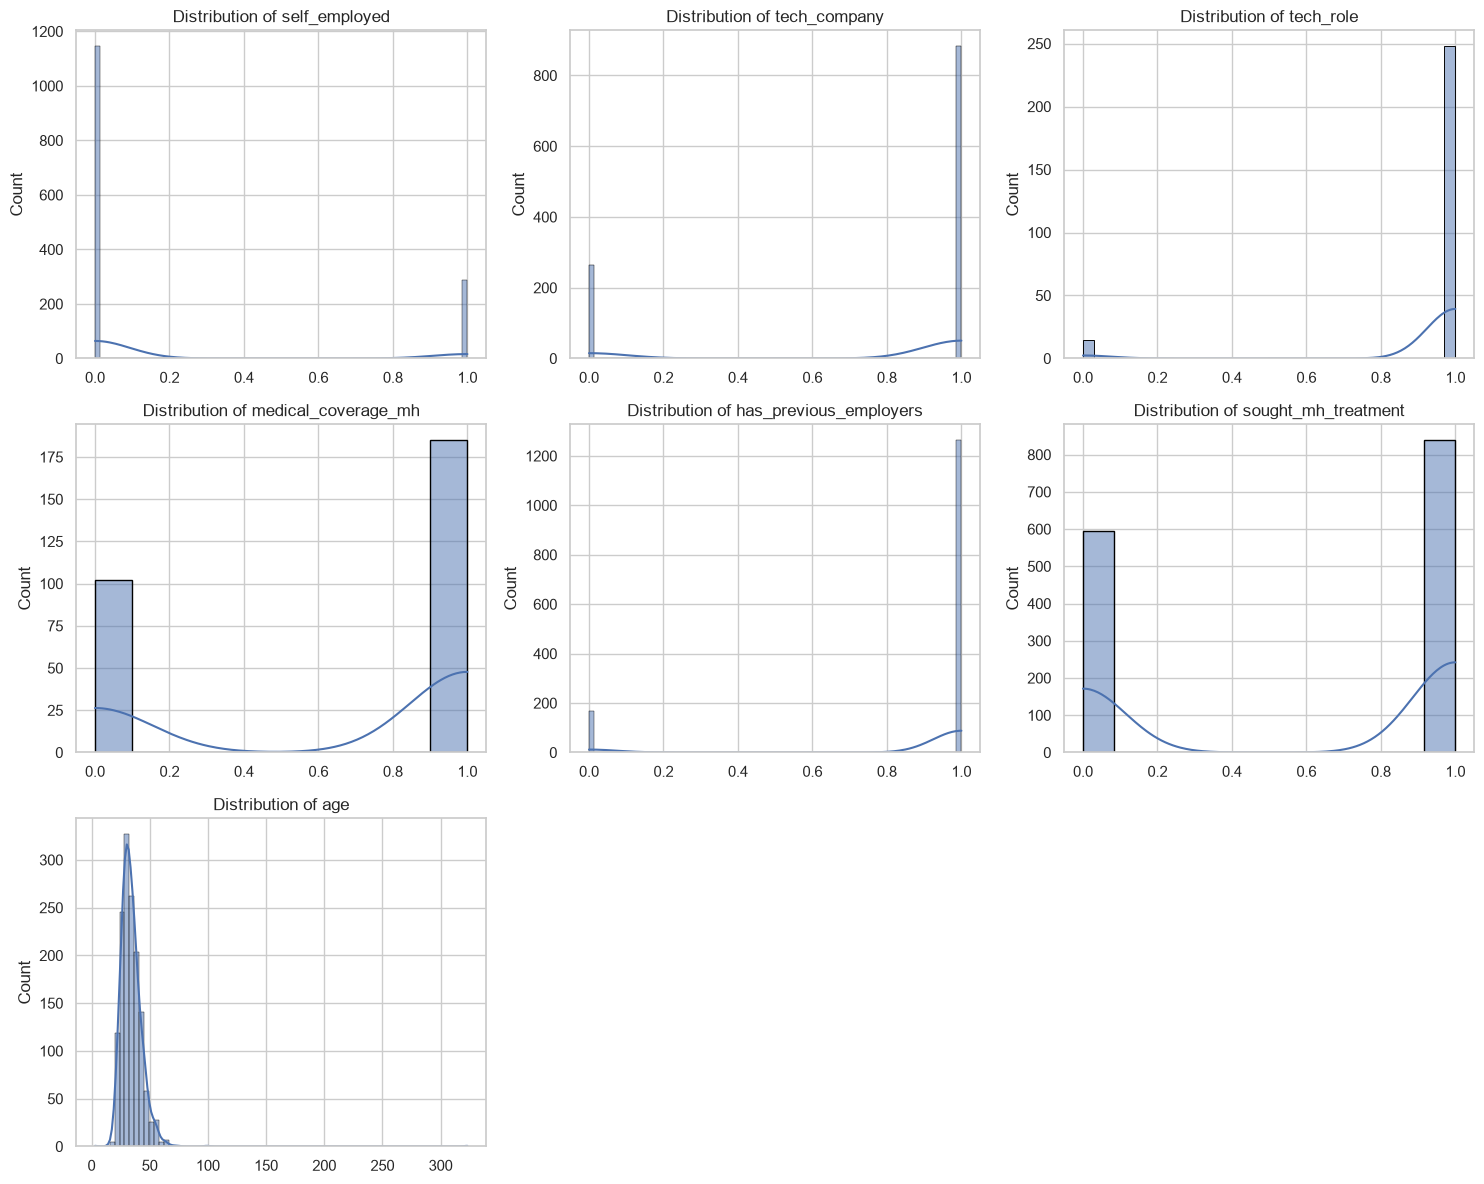

In [7]:
# 1. Filter out only numerical columns
num_cols = df_copy.select_dtypes(include=['number']).columns
n_cols = len(num_cols)

# 2. Dynamically calculate grid dimensions (aiming for 3 columns wide)
grid_cols = 3
grid_rows = math.ceil(n_cols / grid_cols)

# 3. Create the figure grid
fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, grid_rows * 4))
axes = axes.flatten()  # Flatten to easily loop with a single index

# 4. Loop through and plot each column
for i, col in enumerate(num_cols):
    sns.histplot(df_copy[col], ax=axes[i], kde=True, edgecolor='black')
    axes[i].set_title(f'Distribution of {col}', fontsize=12)
    axes[i].set_xlabel('')

# 5. Hide any unused empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



In [26]:
# 1. Select text/categorical features ensuring compatibility across version updates
cat_cols = df_copy.select_dtypes(include=['object', 'string', 'category']).columns
n_cols = len(cat_cols)

# 2. Dynamically calculate grid dimensions (3 columns wide)
grid_cols = 3
grid_rows = math.ceil(n_cols / grid_cols)

# 3. Create one single giant figure
fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(22, grid_rows * 7.5)) # Increased row height multiplier slightly for wrapped text
axes = axes.flatten()

# 4. Plot distributions on the single grid
for i, col in enumerate(cat_cols):
    order = df_copy[col].value_counts().index
    
    if len(order) > 7:
        order = order[:7]
        title_suffix = " (Top 7)"
    else:
        title_suffix = ""
        
    sns.countplot(
        data=df_copy, 
        x=col, 
        ax=axes[i], 
        order=order, 
        hue=col, 
        legend=False, 
        palette='muted', 
        edgecolor='black'
    )
    
    clean_title = col.replace('_', ' ').title() + title_suffix
    axes[i].set_title(clean_title, fontsize=18, fontweight='bold')
    
    # Set ticks explicitly before modifying strings to solve FixedLocator warning
    ticks = range(len(order))
    axes[i].set_xticks(ticks)
    
    # Updated: Wrap long string items at a max character width matching 'United States of America' (24 chars)
    wrapped_labels = ["\n".join(textwrap.wrap(str(label), width=24)) for label in order]
    axes[i].set_xticklabels(wrapped_labels, rotation=45, ha='right', fontsize=10)
    
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

# 5. Automatically remove any unused subplots at the bottom of the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 6. Strict spacing override to stop title-to-axis clipping
plt.tight_layout()
fig.subplots_adjust(hspace=0.9, wspace=0.3) # Increased hspace to comfortably fit multi-line wrapped text labels

plt.show()

In [28]:
pd.DataFrame({
    "data_type": df_copy.dtypes.astype(str),
    "non_missing": df_copy.notna().sum(),
    "missing_count": df_copy.isna().sum(),
    "missing_percentage": (df_copy.isna().mean() * 100).round(2),
    "unique_values": df_copy.nunique(dropna=True)
}).sort_values("missing_percentage", ascending=False)

,data_type,non_missing,missing_count,missing_percentage,unique_values
client_reveal_neg_impact,str,144,1289,89.95,3
mh_productivity_pct,str,204,1229,85.76,4
tech_role,float64,263,1170,81.65,2
medical_coverage_mh,float64,287,1146,79.97,2
reveal_mh_clients,str,287,1146,79.97,5
reveal_mh_coworkers,str,287,1146,79.97,5
coworker_reveal_neg_impact,str,287,1146,79.97,4
know_external_resources,str,287,1146,79.97,3
mh_productivity_affected,str,287,1146,79.97,4
suspected_conditions,str,322,1111,77.53,99


In [29]:
print(f"Exact duplicate rows: {df_copy.duplicated().sum():,}")

Exact duplicate rows: 0


In [30]:
[
    (df_copy.columns[i], df_copy.columns[j])
    for i in range(df_copy.shape[1])
    for j in range(i + 1, df_copy.shape[1])
    if df_copy.iloc[:, i].equals(df_copy.iloc[:, j])
]

[]

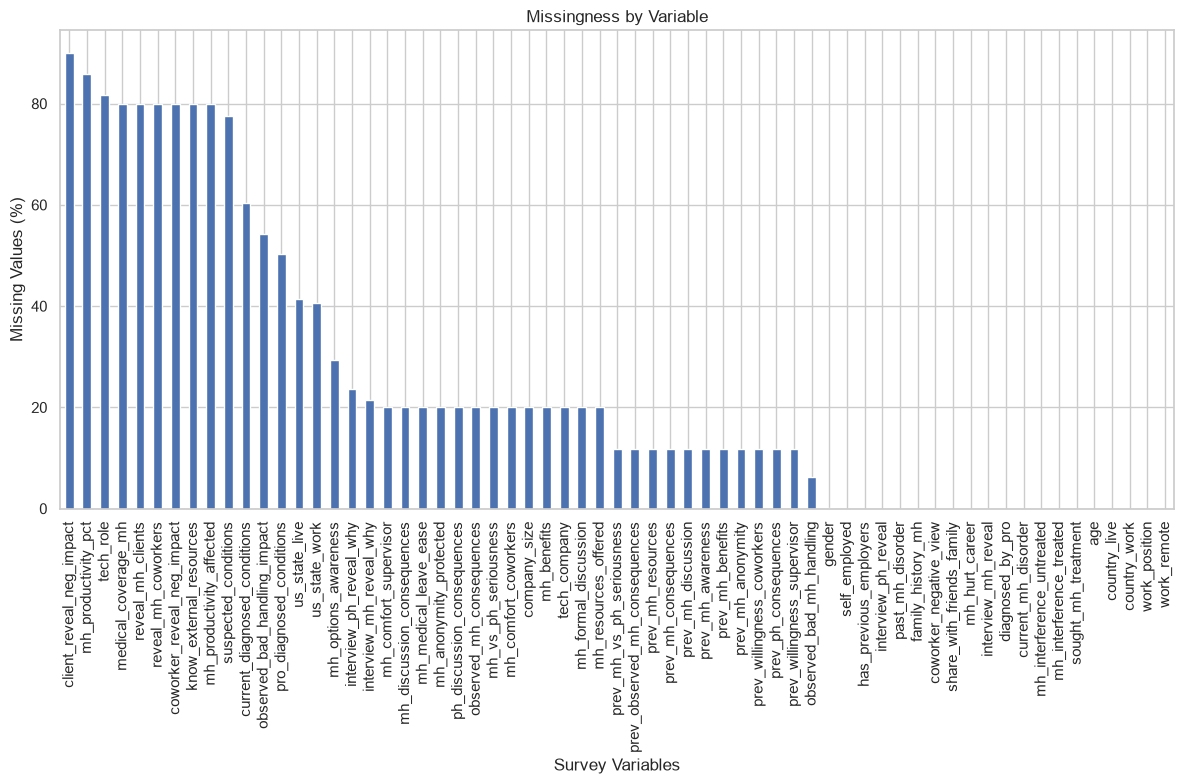

In [46]:
(
    df_copy.isna().mean()
    .sort_values(ascending=False)
    .mul(100)
    .plot(
        kind="bar",
        figsize=(12, 8),
        title="Missingness by Variable"
    )
)

plt.ylabel("Missing Values (%)")
plt.xlabel("Survey Variables")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "missingness_by_colum.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

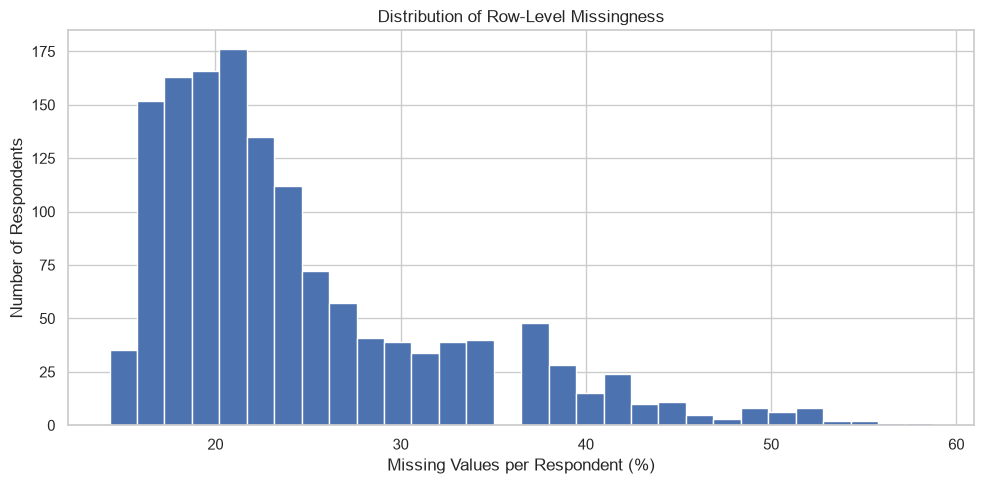

In [40]:
(
    df_copy.isna().mean(axis=1)
    .mul(100)
    .plot(
        kind="hist",
        bins=30,
        figsize=(10, 5),
        title="Distribution of Row-Level Missingness"
    )
)

plt.xlabel("Missing Values per Respondent (%)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "row_missingness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [47]:
pd.crosstab(
    df_copy["self_employed"],
    df_copy["mh_benefits"].isna(),
    margins=True
)

mh_benefits,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


In [49]:
pd.crosstab(
    df_copy["self_employed"],
    df_copy["tech_company"].isna(),
    margins=True
)

tech_company,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


In [51]:
pd.crosstab(
    df_copy["self_employed"],
    df_copy["company_size"].isna(),
    margins=True
)

company_size,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


In [53]:
pd.crosstab(
    df_copy["has_previous_employers"],
    df_copy["prev_mh_benefits"].isna(),
    margins=True
)

prev_mh_benefits,False,True,All
has_previous_employers,,,
0,0,169,169
1,1264,0,1264
All,1264,169,1433


In [56]:
pd.crosstab(
    df_copy["self_employed"],
    df_copy["medical_coverage_mh"].isna(),
    margins=True
)

medical_coverage_mh,False,True,All
self_employed,,,
0,0,1146,1146
1,287,0,287
All,287,1146,1433


In [57]:
pd.crosstab(
    df_copy["mh_productivity_affected"],
    df_copy["mh_productivity_pct"].isna(),
    margins=True
)

mh_productivity_pct,False,True,All
mh_productivity_affected,,,
No,0,14,14
Not applicable to me,0,31,31
Unsure,0,38,38
Yes,204,0,204
All,204,83,287


In [58]:
pd.crosstab(
    df_copy["observed_bad_mh_handling"],
    df_copy["observed_bad_handling_impact"],
    margins=True,
    dropna=False
)

observed_bad_handling_impact,Maybe,No,Yes,NaN,All
observed_bad_mh_handling,,,,,
Maybe/Not sure,82,137,53,74,346
No,0,0,0,567,567
"Yes, I experienced",33,41,65,28,167
"Yes, I observed",62,56,128,18,264
NaN,0,0,0,89,89
All,177,234,246,776,1433


In [60]:
df_copy["age"].describe()

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: age, dtype: float64

In [63]:
df_copy.loc[
    ~df_copy["age"].between(18, 75),
    ["age", "gender"]
]

,age,gender
93,17,male
372,99,Other
564,323,Male
656,3,Male
808,15,male


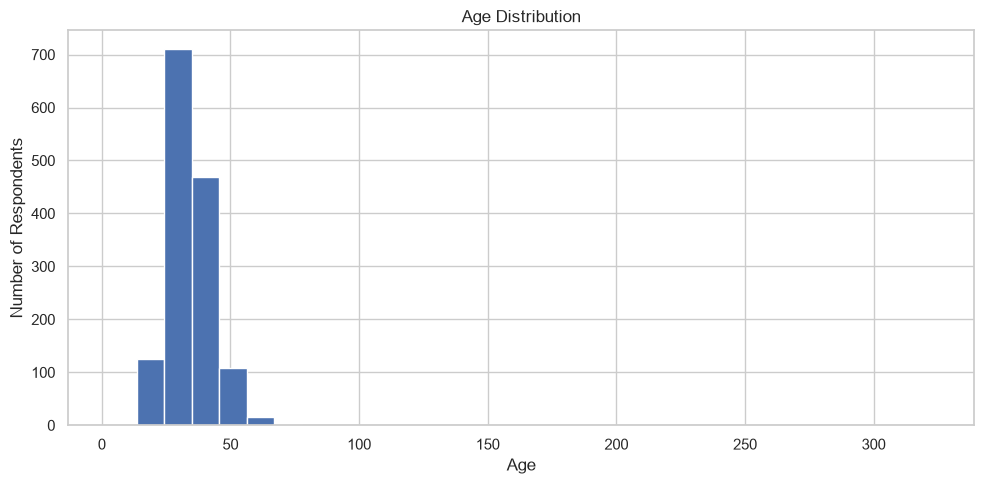

In [65]:
df_copy["age"].plot(
    kind="hist",
    bins=30,
    figsize=(10, 5),
    title="Age Distribution"
)

plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [66]:
(
    df_copy["gender"]
    .value_counts(dropna=False)
    .to_frame("frequency")
)

,frequency
gender,
Male,610
male,249
Female,153
female,95
M,86
m,79
F,38
f,23
Male,11


In [67]:
df_copy.loc[
    df_copy["gender"].isna()
    | df_copy["gender"].astype(str).str.contains(r"\|", regex=True), ["gender"]
]

,gender
302,NaN
643,NaN
925,M|
1312,NaN


In [68]:
pd.DataFrame({
    "pipe_response_count": df_copy.apply(
        lambda column: column.astype("string").str.contains(
            r"\|", regex=True, na=False
        ).sum()
    ),
    "unique_values": df_copy.nunique(dropna=True),
    "missing_percentage": df_copy.isna().mean().mul(100).round(2)
}).query("pipe_response_count > 0")

,pipe_response_count,unique_values,missing_percentage
current_diagnosed_conditions,367,128,60.36
suspected_conditions,207,99,77.53
pro_diagnosed_conditions,392,116,50.38
gender,1,70,0.21
work_position,616,264,0.00


In [70]:
for column in [
    "current_diagnosed_conditions",
    "suspected_conditions",
    "pro_diagnosed_conditions"
]:
    print(f"\n{column}")
    display(
        df_copy[column]
        .dropna()
        .astype(str)
        .str.split("|")
        .explode()
        .str.strip()
        .value_counts()
        .to_frame("frequency")
    )


current_diagnosed_conditions


,frequency
current_diagnosed_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",412
"Anxiety Disorder (Generalized, Social, Phobia, etc)",345
Attention Deficit Hyperactivity Disorder,121
Post-traumatic Stress Disorder,69
Obsessive-Compulsive Disorder,45
Substance Use Disorder,39
Stress Response Syndromes,38
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",35
Addictive Disorder,35



suspected_conditions


,frequency
suspected_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",219
"Anxiety Disorder (Generalized, Social, Phobia, etc)",192
Attention Deficit Hyperactivity Disorder,58
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",42
Stress Response Syndromes,40
Obsessive-Compulsive Disorder,30
Post-traumatic Stress Disorder,26
Addictive Disorder,24
Substance Use Disorder,16



pro_diagnosed_conditions


,frequency
pro_diagnosed_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",526
"Anxiety Disorder (Generalized, Social, Phobia, etc)",373
Attention Deficit Hyperactivity Disorder,134
Post-traumatic Stress Disorder,70
Obsessive-Compulsive Disorder,40
Stress Response Syndromes,31
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",28
Substance Use Disorder,26
"Eating Disorder (Anorexia, Bulimia, etc)",18


In [71]:
(
    df_copy["work_position"]
    .dropna()
    .astype(str)
    .str.split("|")
    .explode()
    .str.strip()
    .value_counts()
    .to_frame("frequency")
)

,frequency
work_position,
Back-end Developer,737
Front-end Developer,502
DevOps/SysAdmin,282
Supervisor/Team Lead,277
Other,187
Support,168
One-person shop,161
Designer,135
Executive Leadership,101


In [72]:
for column in ["interview_ph_reveal_why", "interview_mh_reveal_why"]:
    print(f"\n{column}")
    print(f"Missing: {df_copy[column].isna().sum():,}")
    print(f"Unique responses: {df_copy[column].nunique(dropna=True):,}")

    display(
        df_copy[column]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
        .head(20)
        .to_frame("frequency")
    )



interview_ph_reveal_why
Missing: 338
Unique responses: 1,085


,frequency
interview_ph_reveal_why,
Not relevant,3
Fear of discrimination,3
I don't know,3
Fear of not getting the job,3
None of their business,2
None of their business.,2
bias,2
honesty,2
"It would depend on the health issue. If there is a health issue that would not immediately affect my job performance, such as diabetes, I would not bring it up during the interview. If it was something more severe, such as narcolepsy, I might bring it up depending on how controlled it was.",1



interview_mh_reveal_why
Missing: 307
Unique responses: 1,080


,frequency
interview_mh_reveal_why,
Stigma,14
Stigma.,10
Same as above,7
See above,4
Fear of discrimination,4
Fear of not getting the job,4
Same reason as above.,3
same as above,3
Same as above.,3


In [73]:
for column in df_copy.select_dtypes(
    include=["object", "string", "str"]
).columns:
    print(f"\n{column}")
    print(
        df_copy[column]
        .value_counts(dropna=False)
        .head(20)
        .to_string()
    )


company_size
company_size
26-100            292
NaN               287
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60

mh_benefits
mh_benefits
Yes                                531
I don't know                       319
NaN                                287
No                                 213
Not eligible for coverage / N/A     83

mh_options_awareness
mh_options_awareness
NaN              420
No               354
I am not sure    352
Yes              307

mh_formal_discussion
mh_formal_discussion
No              813
NaN             287
Yes             230
I don't know    103

mh_resources_offered
mh_resources_offered
No              531
I don't know    320
Yes             295
NaN             287

mh_anonymity_protected
mh_anonymity_protected
I don't know    742
Yes             320
NaN             287
No               84

mh_medical_leave_ease
mh_medical_leave_ease
NaN                           287
Somewhat easy       

In [75]:
pd.crosstab(
    df_copy["country_live"],
    df_copy["country_work"],
    margins=True
)

country_work,Afghanistan,Argentina,Australia,Austria,Bangladesh,Belgium,Bosnia and Herzegovina,Brazil,Brunei,Bulgaria,Canada,Chile,China,Colombia,Costa Rica,Czech Republic,Denmark,Ecuador,Estonia,Finland,France,Germany,Greece,Guatemala,Hungary,India,Iran,Ireland,Israel,Italy,Japan,Lithuania,Mexico,Netherlands,New Zealand,Norway,Other,Pakistan,Poland,Romania,Russia,Serbia,Slovakia,South Africa,Spain,Sweden,Switzerland,Turkey,United Arab Emirates,United Kingdom,United States of America,Venezuela,Vietnam,All
country_live,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Afghanistan,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2
Algeria,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1
Argentina,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Australia,0,0,34,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,35
Austria,0,0,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4
Bangladesh,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Belgium,0,0,0,0,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5
Bosnia and Herzegovina,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
Brazil,0,0,0,0,0,0,0,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10


In [78]:
print(
    "Respondents whose country of residence differs from "
    "country of work:",
    (
        df_copy["country_live"]
        != df_copy["country_work"]
    ).sum()
)

Respondents whose country of residence differs from country of work: 26


In [79]:
pd.DataFrame({
    "residence_state_missing": df_copy["us_state_live"].isna(),
    "work_state_missing": df_copy["us_state_work"].isna()
}).sum()

residence_state_missing    593
work_state_missing         582
dtype: int64

In [80]:
pd.crosstab(
    df_copy["country_live"].eq("United States of America"),
    df_copy["us_state_live"].notna()
)

us_state_live,False,True
country_live,,
False,593,0
True,0,840


In [81]:
pd.crosstab(
    df_copy["country_work"].eq("United States of America"),
    df_copy["us_state_work"].notna()
)

us_state_work,False,True
country_work,,
False,582,0
True,0,851


In [83]:
pd.crosstab(
    df_copy["self_employed"],
    df_copy["company_size"],
    margins=True
)

company_size,1-5,100-500,26-100,500-1000,6-25,More than 1000,All
self_employed,,,,,,,
0,60,248,292,80,210,256,1146
All,60,248,292,80,210,256,1146


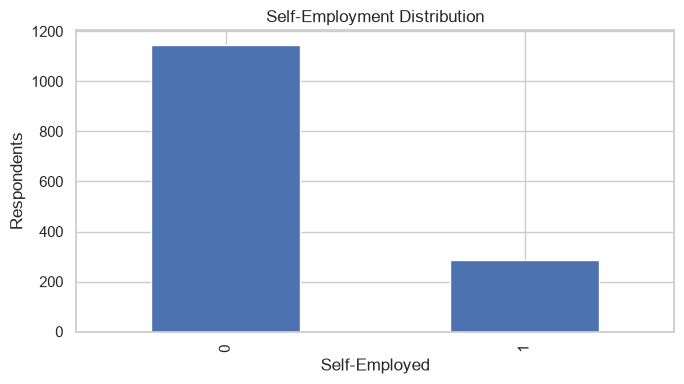

In [84]:
df_copy["self_employed"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Self-Employment Distribution"
)

plt.xlabel("Self-Employed")
plt.ylabel("Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "self_employment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [85]:
pd.crosstab(
    df_copy["tech_company"],
    df_copy["tech_role"],
    margins=True,
    dropna=False
)

tech_role,0.0,1.0,NaN,All
tech_company,,,,
0.0,15,248,0,263
1.0,0,0,883,883
NaN,0,0,287,287
All,15,248,1170,1433


In [86]:
for column in [
    "family_history_mh",
    "past_mh_disorder",
    "current_mh_disorder",
    "diagnosed_by_pro",
    "sought_mh_treatment",

]:
    print(f"\n{column}")
    display(
        df_copy[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


family_history_mh


,frequency
family_history_mh,
Yes,670
No,488
I don't know,275



past_mh_disorder


,frequency
past_mh_disorder,
Yes,736
No,451
Maybe,246



current_mh_disorder


,frequency
current_mh_disorder,
Yes,575
No,531
Maybe,327



diagnosed_by_pro


,frequency
diagnosed_by_pro,
No,717
Yes,716



sought_mh_treatment


,frequency
sought_mh_treatment,
1,839
0,594


In [87]:
for column in [
    "mh_productivity_affected",
    "mh_interference_treated",
    "mh_interference_untreated"
]:
    print(f"\n{column}")
    display(
        df_copy[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


mh_productivity_affected


,frequency
mh_productivity_affected,
NaN,1146
Yes,204
Unsure,38
Not applicable to me,31
No,14



mh_interference_treated


,frequency
mh_interference_treated,
Not applicable to me,557
Sometimes,369
Rarely,322
Never,120
Often,65



mh_interference_untreated


,frequency
mh_interference_untreated,
Often,538
Not applicable to me,468
Sometimes,363
Rarely,52
Never,12


In [88]:
pd.crosstab(
    df_copy["mh_interference_treated"],
    df_copy["mh_interference_untreated"],
    margins=True
)

mh_interference_untreated,Never,Not applicable to me,Often,Rarely,Sometimes,All
mh_interference_treated,,,,,,
Never,9,1,38,18,54,120
Not applicable to me,1,452,35,8,61,557
Often,0,1,56,3,5,65
Rarely,1,5,169,20,127,322
Sometimes,1,9,240,3,116,369
All,12,468,538,52,363,1433


In [89]:
for column in [
    "mh_discussion_consequences",
    "ph_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "mh_hurt_career",
    "coworker_negative_view",
    "interview_ph_reveal",
    "interview_mh_reveal"
]:
    print(f"\n{column}")
    display(
        df_copy[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


mh_discussion_consequences


,frequency
mh_discussion_consequences,
Maybe,487
No,438
NaN,287
Yes,221



ph_discussion_consequences


,frequency
ph_discussion_consequences,
No,837
NaN,287
Maybe,268
Yes,41



mh_comfort_coworkers


,frequency
mh_comfort_coworkers,
Maybe,479
No,392
NaN,287
Yes,275


... (6 outputs left out)


interview_ph_reveal


,frequency
interview_ph_reveal,
Maybe,633
No,441
Yes,359



interview_mh_reveal


,frequency
interview_mh_reveal,
No,883
Maybe,438
Yes,112


In [90]:
for column in [
    "mh_benefits",
    "mh_formal_discussion",
    "mh_resources_offered",
    "mh_anonymity_protected",
    "mh_vs_ph_seriousness",
    "observed_mh_consequences",
    "observed_bad_mh_handling"
]:
    print(f"\n{column}")
    display(
        df_copy[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


mh_benefits


,frequency
mh_benefits,
Yes,531
I don't know,319
NaN,287
No,213
Not eligible for coverage / N/A,83



mh_formal_discussion


,frequency
mh_formal_discussion,
No,813
NaN,287
Yes,230
I don't know,103



mh_resources_offered


,frequency
mh_resources_offered,
No,531
I don't know,320
Yes,295
NaN,287


... (4 outputs left out)


observed_mh_consequences


,frequency
observed_mh_consequences,
No,1048
NaN,287
Yes,98



observed_bad_mh_handling


,frequency
observed_bad_mh_handling,
No,567
Maybe/Not sure,346
"Yes, I observed",264
"Yes, I experienced",167
NaN,89


In [91]:
(
    df_copy["work_remote"]
    .value_counts(dropna=False)
    .to_frame("frequency")
)

,frequency
work_remote,
Sometimes,757
Always,343
Never,333


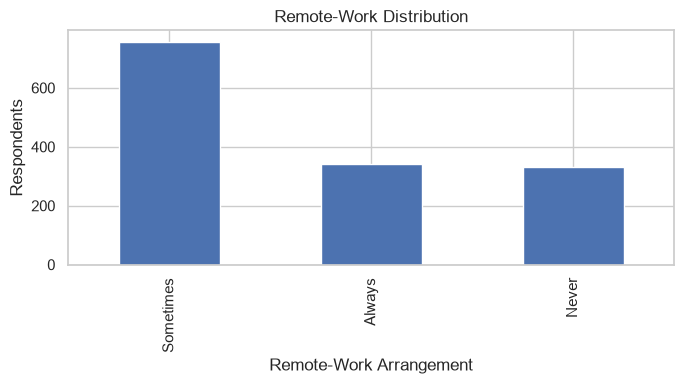

In [92]:
df_copy["work_remote"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Remote-Work Distribution"
)

plt.xlabel("Remote-Work Arrangement")
plt.ylabel("Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "remote_work_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [93]:
binary = [
    # Survey Routing Gatekeepers: Strict 1/0 variables that dynamically change 
    # which sections of the survey a respondent is served.
    "self_employed?",  # Separates freelancers/business owners from enterprise employees
    "has_previous_employer",  # If 0, skips all historical workplace questions
]

nominal = [
    # Current Employer / Workplace Dynamics
    # Tracks basic company ecosystem attributes and high-level structure.
    "tech_company",
    "tech_role",
    
    # Workplace Benefits & Awareness
    # Evaluates the visibility and availability of corporate mental health support.
    "mh_benefits",
    "mh_options_awareness",
    "mh_formal_discussion",
    "mh_resources_offered",
    "mh_anonymity_protected",
    
    # Internal Psychological Safety & Workplace Culture
    # Captures current employee comfort levels and perceived corporate blowback.
    "mh_discussion_consequences",
    "ph_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "mh_vs_ph_seriousness",
    "observed_mh_consequences",
    "medical_coverage_mh",
    "know_external_resources",
    
    # Disclosures & Productivity Impact
    # Conditional logic loops evaluating external interactions vs internal realities.
    "reveal_mh_clients",
    "client_reveal_neg_impact",
    "reveal_mh_coworkers",
    "coworker_reveal_neg_impact",
    "mh_productivity_affected",
    
    # Previous Employers (Historical Workplace Context)
    # Mirror questions to current employer dynamics, evaluating past career environments.
    "prev_mh_benefits",
    "prev_mh_awareness",
    "prev_mh_discussion",
    "prev_mh_resources",
    "prev_mh_anonymity",
    "prev_mh_consequences",
    "prev_ph_consequences",
    "prev_willingness_coworkers",
    "prev_willingness_supervisor",
    "prev_mh_vs_ph_seriousness",
    "prev_observed_mh_consequences",
    
    # Interviews, Career, Stigma
    # Assesses prospective hiring biases, public stigma, and general industry barriers.
    "interview_ph_reveal",
    "interview_mh_reveal",
    "mh_hurt_career",
    "coworker_negative_view",
    "observed_bad_mh_handling",
    
    # Medical History & Diagnostics
    # Personal health indicators and multi-select condition buckets (e.g., Anxiety, Depression, ADHD).
    "family_history_mh",
    "past_mh_disorder",
    "current_mh_disorder",
    "current_diagnosed_conditions",
    "suspected_conditions",
    "diagnosed_by_pro",
    "pro_diagnosed_conditions",
    "sought_mh_treatment",
    
    # Demographics & Work Type
    # High-level regional, biological, and technical tracking features.
    "country_live",
    "us_state_live",
    "country_work",
    "us_state_work",
    "work_position",
    "work_remote"
]

ordinal = [
    # Sized & Scaled Continuous Categories
    # Features that follow a clear linear order, ranging from company size brackets 
    # to sequential degrees of frequency and willingness scales.
    "company_size",  # Company size ranges (e.g., 1-5 to 1000+)
    "mh_medical_leave_ease",  # Ease scale (Very Easy to Very Difficult)
    "mh_productivity_pct",  # Impact brackets (1-20% to 81-100%)
    "share_with_friends_family",  # Numeric Likert scale (0-10 or 1-5 scale)
    "observed_bad_handling_impact",  # Impact magnitude scale
    "mh_interference_treated",  # Frequency scale (Never, Rarely, Sometimes, Often)
    "mh_interference_untreated"   # Frequency scale (Never, Rarely, Sometimes, Often)
]

numeric = [
    # Continuous Mathematical Metrics
    "age"  # Numerical integer value; contains outlier entry noise needing clean-up filters
]

free_text = [
    # Qualitative / Unstructured String Inputs
    # Open-ended responses clarifying specific interview-stage safety boundaries.
    "interview_ph_reveal_why",    # Context for physical health disclosures during prospective interviews
    "interview_mh_reveal_why"  # Context for mental health disclosures during prospective interviews
]

routing_gates = {
    # 1. Employment Status Switch
    "self_employed": [
        "tech_company",
        "tech_role",
        "mh_benefits",
        "mh_options_awareness",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "mh_vs_ph_seriousness",
        "observed_mh_consequences",
        "medical_coverage_mh" # Only asked if Self-Employed = 1
    ],
    
    # 2. Historical Career Switch
    "has_previous_employers": [
        "prev_mh_benefits",
        "prev_mh_awareness",
        "prev_mh_discussion",
        "prev_mh_resources",
        "prev_mh_anonymity",
        "prev_mh_consequences",
        "prev_ph_consequences",
        "prev_willingness_coworkers",
        "prev_willingness_supervisor",
        "prev_mh_vs_ph_seriousness",
        "prev_observed_mh_consequences"
    ],
    
    # 3. Personal History Switch
    "current_mh_disorder": [
        "current_diagnosed_conditions",
        "suspected_conditions",
        "mh_productivity_affected"
    ],
    
    # 4. Productivity Switch
    "mh_productivity_affected": [
        "mh_productivity_pct"
    ],
    
    # 5. Professional Medical Validation Switch
    "diagnosed_by_pro": [
        "pro_diagnosed_conditions"
    ]
}

selected_features = [
    "self_employed",
    "has_previous_employers",
    "tech_company",
    "work_remote",
    "company_size",
    "mh_benefits",
    "mh_medical_leave_ease",
    "mh_vs_ph_seriousness",
    "mh_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "interview_mh_reveal",
    "mh_hurt_career",
    "family_history_mh",
    "current_mh_disorder",
    "sought_mh_treatment",
    "age"
]


In [95]:
df_copy.to_csv("../data/processed/mental-heath-in-tech-2016-clean.csv", index=False)